In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import zipfile
import os

zip_file = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/fake_news_data')

print(os.listdir('/content/fake_news_data'))

['Fake.csv', 'True.csv']


In [ ]:
import os

for root, dirs, files_list in os.walk('/content/fake_news_data'):
    for file in files_list:
        print(os.path.join(root, file))

/content/fake_news_data/Fake.csv
/content/fake_news_data/True.csv


In [ ]:
import pandas as pd

fake_df = pd.read_csv('/content/fake_news_data/Fake.csv')
true_df = pd.read_csv('/content/fake_news_data/True.csv')

print("Fake News Dataset Shape:", fake_df.shape)
print("Real News Dataset Shape:", true_df.shape)

print("\nFake News Columns:")
print(fake_df.columns)

print("\nReal News Columns:")
print(true_df.columns)

Fake News Dataset Shape: (23481, 4)
Real News Dataset Shape: (21417, 4)

Fake News Columns:
Index(['title', 'text', 'subject', 'date'], dtype='object')

Real News Columns:
Index(['title', 'text', 'subject', 'date'], dtype='object')


In [ ]:
print("Fake News Samples:")
display(fake_df.head(3))

print("Real News Samples:")
display(true_df.head(3))

Fake News Samples:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"


Real News Samples:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"


In [ ]:
# Add labels to both datasets
fake_df['label'] = 0
true_df['label'] = 1

# Combine both datasets
df = pd.concat([fake_df, true_df], ignore_index=True)

# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Display dataset information
print("Combined Dataset Shape:", df.shape)
print("\nLabel Distribution:")
print(df['label'].value_counts())

print("\nSample Records:")
display(df[['title', 'text', 'label']].head())

Combined Dataset Shape: (44898, 5)

Label Distribution:
label
0    23481
1    21417
Name: count, dtype: int64

Sample Records:


,title,text,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",1


In [ ]:
print("Missing values:")
print(df[['title', 'text', 'label']].isnull().sum())

print("\nDuplicate rows:", df.duplicated(subset=['title', 'text']).sum())

Missing values:
title    0
text     0
label    0
dtype: int64

Duplicate rows: 5793


In [ ]:
# Remove duplicate news articles
df = df.drop_duplicates(subset=['title', 'text'])

# Remove rows with empty title or text, if any
df = df.dropna(subset=['title', 'text'])

# Remove rows containing blank text
df = df[
    df['title'].str.strip().ne('') &
    df['text'].str.strip().ne('')
].copy()

# Reset index
df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("\nLabel distribution:")
print(df['label'].value_counts())

print("\nRemaining duplicates:",
      df.duplicated(subset=['title', 'text']).sum())

Dataset shape after cleaning: (38658, 5)

Label distribution:
label
1    21196
0    17462
Name: count, dtype: int64

Remaining duplicates: 0


In [ ]:
# Combine title and news text
df['content'] = df['title'] + ' ' + df['text']

# Keep only the columns needed for our project
df = df[['content', 'label']]

# Check the result
print(df.head(3))
print("\nDataset shape:", df.shape)

                                             content  label
0  Ben Stein Calls Out 9th Circuit Court: Committ...      0
1  Trump drops Steve Bannon from National Securit...      1
2  Puerto Rico expects U.S. to lift Jones Act shi...      1

Dataset shape: (38658, 2)


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['content'] = df['content'].apply(clean_text)

print(df['content'].head(3))

0    ben stein calls out th circuit court committed...
1    trump drops steve bannon from national securit...
2    puerto rico expects u s to lift jones act ship...
Name: content, dtype: object


In [ ]:
from sklearn.model_selection import train_test_split

X = df['content']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 30926
Testing samples: 7732


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Set vocabulary size and sequence length
vocab_size = 20000
max_length = 300

# Create tokenizer
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")

# Fit tokenizer only on training text
tokenizer.fit_on_texts(X_train)

# Convert text into sequences of integers
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("First text:")
print(X_train.iloc[0][:200])

print("\nFirst numerical sequence:")
print(X_train_seq[0][:30])

First text:
wingnut pastor the pope is confused should ask forgiveness from trump video donald trump decided to war with the one person most politicians have enough sense not to touch the pope pope francis was as

First numerical sequence:
[1, 3090, 2, 1836, 12, 4871, 112, 1026, 9191, 26, 13, 131, 68, 13, 734, 3, 220, 17, 2, 52, 468, 126, 1137, 25, 478, 1284, 24, 3, 3102, 2]


In [ ]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training padded shape:", X_train_pad.shape)
print("Testing padded shape:", X_test_pad.shape)

Training padded shape: (30926, 300)
Testing padded shape: (7732, 300)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Build the LSTM model
model = Sequential([
    Embedding(input_dim=20000, output_dim=128),
    LSTM(64, dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.build(input_shape=(None, 300))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,611,521 (9.96 MB)

 Trainable params: 2,611,521 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
435/435 ━━━━━━━━━━━━━━━━━━━━ 181s 410ms/step - accuracy: 0.8136 - loss: 0.4246 - val_accuracy: 0.5480 - val_loss: 0.6903
Epoch 2/5
435/435 ━━━━━━━━━━━━━━━━━━━━ 175s 403ms/step - accuracy: 0.5593 - loss: 0.6855 - val_accuracy: 0.5480 - val_loss: 0.6885
Epoch 3/5
435/435 ━━━━━━━━━━━━━━━━━━━━ 203s 405ms/step - accuracy: 0.6295 - loss: 0.5814 - val_accuracy: 0.8726 - val_loss: 0.3640
Epoch 4/5
435/435 ━━━━━━━━━━━━━━━━━━━━ 177s 407ms/step - accuracy: 0.8600 - loss: 0.4116 - val_accuracy: 0.7798 - val_loss: 0.4226
Epoch 5/5
435/435 ━━━━━━━━━━━━━━━━━━━━ 182s 418ms/step - accuracy: 0.8732 - loss: 0.3500 - val_accuracy: 0.9412 - val_loss: 0.1965


In [ ]:
# Evaluate the model on unseen test data
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=1
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

242/242 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.9401 - loss: 0.2002
Test Loss: 0.2002
Test Accuracy: 94.01 %


242/242 ━━━━━━━━━━━━━━━━━━━━ 19s 78ms/step
Accuracy: 0.9401

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.93      0.94      0.93      3493
   Real News       0.95      0.94      0.95      4239

    accuracy                           0.94      7732
   macro avg       0.94      0.94      0.94      7732
weighted avg       0.94      0.94      0.94      7732



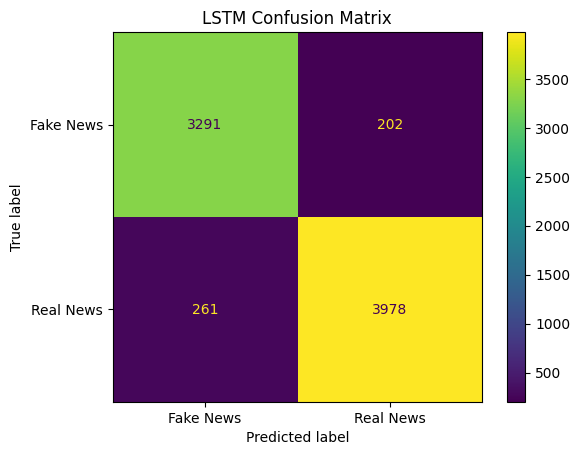

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions
y_prob = model.predict(X_test_pad)
y_pred = (y_prob >= 0.5).astype(int).ravel()

# Evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake News", "Real News"]
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake News", "Real News"]
)

disp.plot()
plt.title("LSTM Confusion Matrix")
plt.show()

242/242 ━━━━━━━━━━━━━━━━━━━━ 15s 60ms/step
              precision    recall  f1-score   support

   Fake News       0.93      0.94      0.93      3493
   Real News       0.95      0.94      0.95      4239

    accuracy                           0.94      7732
   macro avg       0.94      0.94      0.94      7732
weighted avg       0.94      0.94      0.94      7732



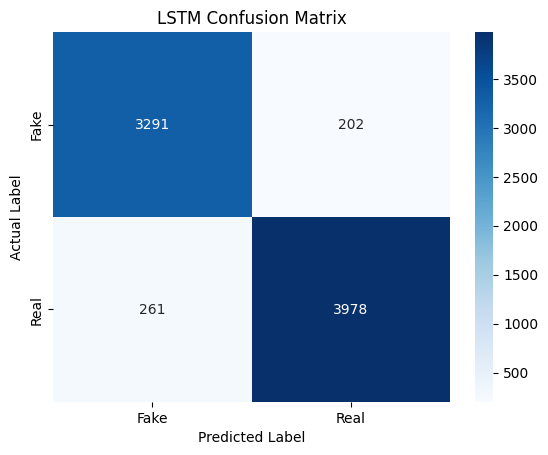

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_prob = model.predict(X_test_pad)
y_pred = (y_prob >= 0.5).astype(int).ravel()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake News", "Real News"]
))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Real'],
    yticklabels=['Fake', 'Real']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('LSTM Confusion Matrix')
plt.show()

In [ ]:
# Save the trained LSTM model
model.save('/content/fake_news_lstm.keras')

# Save the tokenizer
import pickle

with open('/content/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [ ]:
from google.colab import files

files.download('/content/fake_news_lstm.keras')
files.download('/content/tokenizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print(os.path.exists('/content/fake_news_lstm.keras'))

True


In [ ]:
from google.colab import files

files.download('/content/fake_news_lstm.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

model_path = '/content/fake_news_lstm.keras'

print("File exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("File size (MB):", round(
        os.path.getsize(model_path) / (1024 * 1024), 2
    ))
else:
    print("Model file is missing.")
    print("Files in /content:")
    print(os.listdir('/content'))

File exists: True
File size (MB): 29.92


In [ ]:
from google.colab import files
files.download('/content/fake_news_lstm.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
import os

shutil.make_archive(
    '/content/fake_news_model',
    'zip',
    root_dir='/content',
    base_dir='fake_news_lstm.keras'
)

print("ZIP exists:", os.path.exists('/content/fake_news_model.zip'))

ZIP exists: True


In [ ]:
from google.colab import files

files.download('/content/fake_news_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>